# 인공신경망을 이용한 MNIST 손글씨 분류
* 교과서 140~153 페이지
* MNIST 데이터셋: 미국 국립표준기술원(NIST)에서 고등학생과 인구조사국 직원 등이 쓴 손글씨를 이용해 만들었으며 딥러닝을 처음 배울 때 많이 사용됨
* 인공신경망


## 1)문제 정의
사람마다 숫자를 쓰는 필체가 달라서 같은 숫자를 쓰더라도 아래 그림처럼 손 글씨의 모양은 조금씩 다르다. 각기 다른 숫자 하나가 주어지면 0부터 9까지의 숫자 중 하나로 분류하는 인공신경망을 만들고자 한다.  <br>
<img src="https://drive.google.com/uc?id=1TV4dVR-46Pw3d7fx6IUuSeck_LqvfTTS" height=320 width=450>

## 2)데이터셋 준비
* mnist 데이터셋은 텐서플로의 케라스에 포함되어 있는 것 사용
* 케라스: 딥러닝 구현을 위해 구글에서 만들 라이브러리로 텐서플로가 있는데, 사용법이 어렵다는 단점이 있음. 이를 보완하기 위해 개발된 것이 케라스임. 텐서플로가 비행기라면 케라스는 이를 조정하는 파일럿에 비유할 수 있음.<br>
<img src="https://drive.google.com/uc?id=1JqzRFJE7raq27u0rc-mbJQ4cQ54ENq2_" height=120 width=450>

In [ ]:
# 라이브러리를 불러와 딥러닝을 위한 환경 준비하기
import tensorflow as tf
from tensorflow import keras
import numpy as np   # 2차원의 이미지를 1차원으로 변환하기 위해 필요
import matplotlib.pyplot as plt   # 데이터 이미지 확인을 위해 필요

In [ ]:
# 훈련 및 테스트 데이터 불러오기
mnist = keras.datasets.mnist   # mnist라는 객체 만듦
(X_train, y_train), (X_test, y_test) = mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
# 데이터 탐색하기
print(X_train.shape, X_test.shape)            # 28X28 크기의 이차원 배열
print(y_train.shape, y_test.shape)            # 일차원 배열
print(f'훈련 데이터: {X_train.shape[0]}개')   # 훈련 데이터 개수
print(f'테스트 데이터: {X_test.shape[0]}개')   # 테스트 데이터 개수

(60000, 28, 28) (10000, 28, 28)
(60000,) (10000,)
훈련 데이터: 60000개
테스트 데이터: 10000개


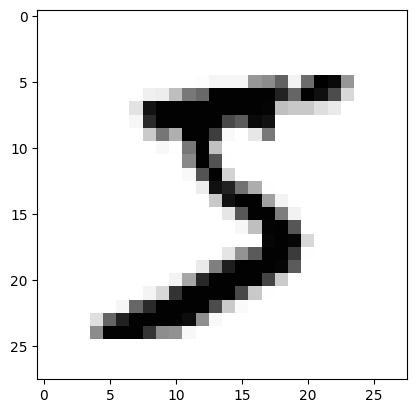

In [ ]:
# 훈련 데이터의 첫 번째 이미지 확인
plt.imshow(X_train[0], cmap = 'Greys')    # 인덱스 번호는 0번부터 사용
plt.show()

In [ ]:
# 첫 번째 이미지의 픽셀값 확인하기
for x in X_train[0]:
    for i in x:
        print(f'{i:^4}', end='')   # f-string으로 4자리씩 픽셀값 나타내기
    print()

 0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  
 0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  
 0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  
 0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  
 0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  
 0   0   0   0   0   0   0   0   0   0   0   0   3   18  18  18 126 136 175  26 166 255 247 127  0   0   0   0  
 0   0   0   0   0   0   0   0   30  36  94 154 170 253 253 253 253 253 225 172 253 242 195  64  0   0   0   0  
 0   0   0   0   0   0   0   49 238 253 253 253 253 253 253 253 253 251  93  82  82  56  39  0   0   0   0   0  
 0   0   0   0   0   0   0   18 219 253 253 253 253 253 198 182 247 241  0   0   0   0   0   0  

In [ ]:
# 첫 번째 이미지의 정답(클래스) 확인하기
print(y_train)   # 훈련 데이터의 정답 배열
print(f'첫 번째 훈련 데이터의 정답 : {y_train[0]}')

[5 0 4 ... 5 6 8]
첫 번째 훈련 데이터의 정답 : 5


## 3)데이터 전처리하기
① 1차원 배열로 변환하기<br>
② 데이터 정규화<br>
③ 원-핫 인코딩하기<br>

### ① 1차원 배열로 변환하기
한 장의 이미지를 기준으로 생각했을 때<br>
28*28 크기의 2차원 배열을 1차원 배열(784)로 형태 변환<br>
reshape()함수 사용<br>
<img src="https://drive.google.com/uc?id=1n7g9iUt353xlNoK5URB4PEKPZ_VhSHaB" height=120 width=450>

In [ ]:
# 2차원을 1차원 배열로 변환하기
# X_train.shape[0] 대신 ‘60000’으로 대체 가능
# 60000장의 사진에 대해 28*28->784 처리
# 즉, (60000, 28, 28) -> (60000, 784)
X_train = X_train.reshape(X_train.shape[0], 784)

# X_test.shape[0] 대신 ‘10000’으로 대체 가능
X_test = X_test.reshape(X_test.shape[0], 784)

# 전처리 후 데이터 배열 형태 확인하기
print(X_train.shape, X_test.shape)

(60000, 784) (10000, 784)


### ② 데이터 정규화

In [ ]:
# 데이터 정규화하기
X_train = X_train / 255.0
X_test = X_test / 255.0

### ③ 원-핫 인코딩하기
0~9 각 숫자를 서로 구별하기 위한 범주형 데이터<br>
범주형 데이터로 인해 인공신경망의 각 층에서 오류가 발생하지 않도록 연산이 가능한 숫자 데이터로 변환<br>
케라스 라이브러리는 원-핫 인코딩으로 데이터를 변환하도록 to_categoricla() 함수 제공<br>
<img src="https://drive.google.com/uc?id=1ZDZCSdtr3aPmAoAdCcG1YEg4Rd_O_Hn8" height=280 width=450>

In [ ]:
# 원-핫 인코딩을 위한 라이브러리 불러오기
from tensorflow.keras.utils import to_categorical

# 원-핫 인코딩하기
# 0~9 숫자 구별하기 위해 10개의 범주 필요
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

# 정규화 결과 확인하기
print(y_train[0])

[0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]


## 4)인공신경망 모델 생성 및 학습
① 인공신경망 구조 만들기<br>
② 인공신경망 학습시키기<br>


### ① 인공신경망 구조 만들기
딥러님 모델과 MNIST의 첫번째 학습 데이터인 '5'의 이미지를 인식하는 과정<br>
※ 활성 함수: 렐루(ReLU), 소프트맥스(softmax) 확인<br>
<img src="https://drive.google.com/uc?id=1NJNiw0_D3eKfjGMKFvXmO7XDH4PHVABG" height=220 width=450>
<br><br>
파라미터 계산하는 방법<br>
<img src="https://drive.google.com/uc?id=1hGT8oTXGEw5i4xZPolr6phspoz14h0wi" height=400 width=450>

In [ ]:
# 인공신경망 구조를 만들기 위한 라이브러리 불러오기
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense   # Dense는 층을 만드는 클래스

# 층을 순서대로 쌓은 형태의 신경망 모델 객체 만들기
model = Sequential()

# 은닉층과 출력층 쌓기
# 1개의 은닉층 만들기
model.add(Dense(100, activation='relu', input_shape=(784, ), name='hidden'))

# 출력층 만들기
model.add(Dense(10, activation='softmax',  name='output'))

# 모델의 정보 확인하기
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden (Dense)                  │ (None, 100)            │        78,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 79,510 (310.59 KB)

 Trainable params: 79,510 (310.59 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# # 인공신경망 모델 객체 만들기 방법2
# # 인공신경망 구조를 만들기 위한 라이브러리 불러오기
# from tensorflow.keras.models import Sequential
# from tensorflow.keras.layers import Dense   # Dense는 층을 만드는 클래스

# # 은닉층과 출력층 쌓기
# dense1 = Dense(100, activation='relu', input_shape=(784, ), name='hidden')
# dense2 = Dense(10, activation='softmax', name='output')

# # 층을 순서대로 쌓은 형태의 신경망 모델 객체 만들기
# model = Sequential([dense1, dense2])

# # 모델의 정보 확인하기
# model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden (Dense)                  │ (None, 100)            │        78,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 79,510 (310.59 KB)

 Trainable params: 79,510 (310.59 KB)

 Non-trainable params: 0 (0.00 B)

### ② 인공신경망 학습시키기
딥러닝 모델의 학습 설계<br>
<img src="https://drive.google.com/uc?id=1ZamMGyHgD4MDwSwvIuHor9PvMUGyR77E" height=120 width=450>


In [ ]:
# 딥러닝 모델의 학습 과정 설정하기
model.compile(loss='categorical_crossentropy',             # 다중 분류 손실함수
              optimizer='adam',                            # 최적화 함수
              metrics=['accuracy'])                        # 평가지표의 정확도

In [ ]:
# 훈련 데이터로 모델 학습시키기
model.fit(X_train, y_train,
         epochs = 100,       # 모든 데이터를 100번 학습
         batch_size = 128,   # 128개의 단위로 학습
         verbose = 2)        # 학습 과정 출력, 2:에포크(epoch)마다 결과를 한 줄씩 표시

Epoch 1/100
469/469 - 3s - 7ms/step - accuracy: 0.8974 - loss: 0.3735
Epoch 2/100
469/469 - 3s - 6ms/step - accuracy: 0.9498 - loss: 0.1765
Epoch 3/100
469/469 - 2s - 4ms/step - accuracy: 0.9636 - loss: 0.1286
Epoch 4/100
469/469 - 2s - 4ms/step - accuracy: 0.9712 - loss: 0.1016
Epoch 5/100
469/469 - 2s - 4ms/step - accuracy: 0.9761 - loss: 0.0828
Epoch 6/100
469/469 - 2s - 4ms/step - accuracy: 0.9795 - loss: 0.0697
Epoch 7/100
469/469 - 2s - 4ms/step - accuracy: 0.9825 - loss: 0.0591
Epoch 8/100
469/469 - 3s - 6ms/step - accuracy: 0.9851 - loss: 0.0502
Epoch 9/100
469/469 - 2s - 4ms/step - accuracy: 0.9876 - loss: 0.0428
Epoch 10/100
469/469 - 2s - 4ms/step - accuracy: 0.9892 - loss: 0.0375
Epoch 11/100
469/469 - 3s - 5ms/step - accuracy: 0.9909 - loss: 0.0324
Epoch 12/100
469/469 - 2s - 4ms/step - accuracy: 0.9924 - loss: 0.0280
Epoch 13/100
469/469 - 2s - 4ms/step - accuracy: 0.9936 - loss: 0.0243
Epoch 14/100
469/469 - 3s - 6ms/step - accuracy: 0.9946 - loss: 0.0212
Epoch 15/100
46

## 5)모델 성능 평가하기
Dense 100의 은닉층 1개를 사용한 모델의 정확도: 0.9807

In [ ]:
# 모델 성능 평가하기
print(model.evaluate(X_test, y_test))
# 소수점 이하 넷째자리까지 출력
print(f'정확도: {model.evaluate(X_test, y_test)[1]: .4}')

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9807 - loss: 0.1304
[0.13044600188732147, 0.9807000160217285]
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9807 - loss: 0.1304
정확도:  0.9807


## 6)은닉층 하나 더 추가한 모델과 성능 비교(P.152~153)
위 모델과 차이점<br>
- 은닉층 2개(Dense 200, Dense 100)
- epoch 200
- 나머지는 모두 동일<br>
<br>
이 모델의 정확도: 0.9821<br>
위 모델의 정확도: 0.9807<br>
이 정도 차이를 '유의미한 차이'라고 할 수 있는가?<br>

In [ ]:
import tensorflow as tf
from tensorflow import keras
import numpy as np

# 데이터 불러오기
mnist = keras.datasets.mnist
(X_train, y_train), (X_test, y_test) = mnist.load_data()

# 2차원을 1차원의 배열로 변환하기
X_train = X_train.reshape(X_train.shape[0], 784)
X_test = X_test.reshape(X_test.shape[0], 784)

# 데이터 정규화하기
X_train = X_train / 255.0
X_test = X_test / 255.0

# 원-핫 인코딩하기
from tensorflow.keras.utils import to_categorical
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

# 은닉층과 출력층 만들기
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
model = Sequential()
model.add(Dense(200, activation='relu', input_shape=(784, ), name='hidden1'))
model.add(Dense(100, activation='relu', name='hidden2'))
model.add(Dense(10, activation='softmax',  name='output'))

# 모델 설정과 학습시키기
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.fit(X_train, y_train, epochs = 200, batch_size = 128, verbose = 2)

# 모델 성능 평가하기
print(model.evaluate(X_test, y_test))
print(f'정확도: {model.evaluate(X_test, y_test)[1]: .4}')

Epoch 1/200
469/469 - 4s - 9ms/step - accuracy: 0.9138 - loss: 0.2959
Epoch 2/200
469/469 - 7s - 14ms/step - accuracy: 0.9661 - loss: 0.1140
Epoch 3/200
469/469 - 3s - 7ms/step - accuracy: 0.9768 - loss: 0.0766
Epoch 4/200
469/469 - 3s - 7ms/step - accuracy: 0.9825 - loss: 0.0565
Epoch 5/200
469/469 - 3s - 7ms/step - accuracy: 0.9873 - loss: 0.0425
Epoch 6/200
469/469 - 5s - 11ms/step - accuracy: 0.9894 - loss: 0.0336
Epoch 7/200
469/469 - 3s - 6ms/step - accuracy: 0.9920 - loss: 0.0257
Epoch 8/200
469/469 - 3s - 7ms/step - accuracy: 0.9935 - loss: 0.0206
Epoch 9/200
469/469 - 5s - 10ms/step - accuracy: 0.9949 - loss: 0.0167
Epoch 10/200
469/469 - 3s - 7ms/step - accuracy: 0.9951 - loss: 0.0157
Epoch 11/200
469/469 - 3s - 7ms/step - accuracy: 0.9958 - loss: 0.0131
Epoch 12/200
469/469 - 3s - 7ms/step - accuracy: 0.9970 - loss: 0.0098
Epoch 13/200
469/469 - 5s - 10ms/step - accuracy: 0.9965 - loss: 0.0108
Epoch 14/200
469/469 - 3s - 7ms/step - accuracy: 0.9968 - loss: 0.0094
Epoch 15/20